# Notebook 1 — Persiapan dan Penggabungan Data

**Proyek:** Analisis SST, Marine Heatwave (MHW), dan Chlorophyll-a di Perairan NTT  
**Tujuan Notebook:** Menginventarisasi file, memeriksa struktur data, menggabungkan file yang kompatibel, memvalidasi kualitas data, dan menyiapkan dataset untuk analisis berikutnya.

---

## Ringkasan Alur Kerja

1. Memuat konfigurasi proyek
2. Inventarisasi dan inspeksi file SST (NOAA OISST v2.1)
3. Penggabungan SST menjadi satu dataset harian 2000–2020
4. Inventarisasi dan inspeksi file chlorophyll-a (ESA CCI OC v6.0)
5. Ekstraksi dan penggabungan chlorophyll-a
6. Pemeriksaan SHP (opsional)
7. Validasi kualitas data dan pembuatan laporan
8. Ekspor dataset terverifikasi

## Data Input
- **SST:** File NetCDF tahunan dari NOAA OISST v2.1 daily AVHRR (`sst_ntt_YYYY.nc`)
- **Chlorophyll-a:** ZIP bulanan berisi NetCDF harian dari ESA CCI OC v6.0
- **SHP:** Batas administrasi NTT (opsional)

## Keluaran yang Diharapkan
- `sst_daily_2000_2020_ntt.nc` — Dataset SST harian gabungan
- `chlorophyll_a_daily_ntt.nc` — Dataset chlorophyll-a harian gabungan
- `data_inventory.csv` — Daftar inventaris semua file
- `data_quality_report.csv` — Laporan kualitas data

---
## 1. Konfigurasi dan Impor Pustaka

Memuat konfigurasi terpusat dari `config/project_config.py` dan pustaka yang diperlukan.  
**Alasan:** Konfigurasi terpusat memudahkan perubahan parameter tanpa mengedit kode analisis.

In [1]:
import sys
import os
import warnings
import zipfile
import tempfile
import io
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from tqdm import tqdm

warnings.filterwarnings('ignore', category=FutureWarning)

# Tambahkan folder config ke path
notebook_dir = Path(os.path.abspath(''))
project_root = notebook_dir.parent
sys.path.insert(0, str(project_root / 'config'))

import project_config as cfg

print("=" * 60)
print("KONFIGURASI PROYEK")
print("=" * 60)
print(f"Project Root     : {cfg.PROJECT_ROOT}")
print(f"Periode SST      : {cfg.SST_START_YEAR}–{cfg.SST_END_YEAR}")
print(f"Bounding Box     : Lon {cfg.LON_MIN}–{cfg.LON_MAX}°E, "
      f"Lat {cfg.LAT_MIN}–{cfg.LAT_MAX}°")
print(f"SST Raw Dir      : {cfg.SST_RAW_DIR}")
print(f"Chla ZIP Dir     : {cfg.CHLA_ZIP_DIR_PRIMARY}")
print(f"Chla NC Dir      : {cfg.CHLA_NC_DIR}")
print(f"Output Dir       : {cfg.PROCESSED_DIR}")
print()

# Buat direktori output jika belum ada
for d in [cfg.PROCESSED_DIR, cfg.INTERIM_DIR, cfg.FIGURES_DIR,
          cfg.TABLES_DIR, cfg.REPORTS_DIR, cfg.LOGS_DIR]:
    d.mkdir(parents=True, exist_ok=True)
    
print("Direktori output siap.")

# Catat versi pustaka
print("\nVersi pustaka:")
for lib_name, lib in [("numpy", np), ("pandas", pd), ("xarray", xr)]:
    print(f"  {lib_name}: {lib.__version__}")
import netCDF4
print(f"  netCDF4: {netCDF4.__version__}")
import matplotlib
print(f"  matplotlib: {matplotlib.__version__}")

KONFIGURASI PROYEK
Project Root     : G:\My Drive\KLIMTROP\PBL
Periode SST      : 2000–2020
Bounding Box     : Lon 117.5–127.5°E, Lat -13.0–-7.0°
SST Raw Dir      : G:\My Drive\KLIMTROP\PBL\data\data_sst_ntt
Chla ZIP Dir     : G:\My Drive\KLIMTROP\PBL\data\chla_ntt_daily
Chla NC Dir      : G:\My Drive\KLIMTROP\PBL\data\raw\chlorophyll_a_nc
Output Dir       : G:\My Drive\KLIMTROP\PBL\data\processed

Direktori output siap.

Versi pustaka:
  numpy: 2.4.4
  pandas: 2.3.0
  xarray: 2026.4.0
  netCDF4: 1.7.4
  matplotlib: 3.10.6


---
## 2. Inventarisasi File SST

Memeriksa file SST yang tersedia, ukurannya, dan tahun yang hilang.  
**Sumber data:** NOAA OISST v2.1 daily AVHRR, resolusi 0.25° (≈ 25 km).  
**Format:** Satu file NetCDF per tahun berisi data harian.

In [2]:
# Inventarisasi file SST
sst_dir = cfg.SST_RAW_DIR
print(f"Mencari file SST di: {sst_dir}")
print()

if not sst_dir.exists():
    raise FileNotFoundError(
        f"Folder SST tidak ditemukan: {sst_dir}\n"
        "Periksa path di config/project_config.py"
    )

# Daftar semua file NetCDF SST
sst_files = sorted(sst_dir.glob("sst_ntt_*.nc"))
print(f"Jumlah file SST ditemukan: {len(sst_files)}")

# Buat tabel inventaris
sst_inventory = []
tahun_tersedia = []

for f in sst_files:
    # Ekstrak tahun dari nama file
    try:
        tahun = int(f.stem.split("_")[-1])
    except ValueError:
        tahun = None
    
    size_mb = f.stat().st_size / (1024 * 1024)
    sst_inventory.append({
        "file": f.name,
        "tahun": tahun,
        "ukuran_MB": round(size_mb, 2),
        "path": str(f)
    })
    if tahun is not None:
        tahun_tersedia.append(tahun)

df_sst_inv = pd.DataFrame(sst_inventory)
print("\nDaftar File SST:")
print(df_sst_inv[["file", "tahun", "ukuran_MB"]].to_string(index=False))

# Cek tahun yang hilang
tahun_target = list(range(cfg.SST_START_YEAR, cfg.SST_END_YEAR + 1))
tahun_hilang = [t for t in tahun_target if t not in tahun_tersedia]

print(f"\nTahun target    : {cfg.SST_START_YEAR}–{cfg.SST_END_YEAR} ({len(tahun_target)} tahun)")
print(f"Tahun tersedia  : {len(tahun_tersedia)}")
if tahun_hilang:
    print(f"⚠️  Tahun HILANG : {tahun_hilang}")
else:
    print("✅ Semua tahun target tersedia.")

Mencari file SST di: G:\My Drive\KLIMTROP\PBL\data\data_sst_ntt

Jumlah file SST ditemukan: 21

Daftar File SST:
           file  tahun  ukuran_MB
sst_ntt_2000.nc   2000       0.70
sst_ntt_2001.nc   2001       0.70
sst_ntt_2002.nc   2002       0.70
sst_ntt_2003.nc   2003       0.70
sst_ntt_2004.nc   2004       0.69
sst_ntt_2005.nc   2005       0.69
sst_ntt_2006.nc   2006       0.69
sst_ntt_2007.nc   2007       0.68
sst_ntt_2008.nc   2008       0.68
sst_ntt_2009.nc   2009       0.67
sst_ntt_2010.nc   2010       0.68
sst_ntt_2011.nc   2011       0.68
sst_ntt_2012.nc   2012       0.68
sst_ntt_2013.nc   2013       0.68
sst_ntt_2014.nc   2014       0.68
sst_ntt_2015.nc   2015       0.68
sst_ntt_2016.nc   2016       0.68
sst_ntt_2017.nc   2017       0.68
sst_ntt_2018.nc   2018       0.68
sst_ntt_2019.nc   2019       0.68
sst_ntt_2020.nc   2020       0.68

Tahun target    : 2000–2020 (21 tahun)
Tahun tersedia  : 21
✅ Semua tahun target tersedia.


---
## 3. Inspeksi Struktur Data SST

Memeriksa nama variabel, dimensi, koordinat, unit, kalender waktu, fill value, dan rentang nilai.  
**PENTING:** Tidak mengasumsikan struktur sebelum inspeksi aktual.

In [3]:
# Inspeksi file SST pertama secara detail
if len(sst_files) == 0:
    raise FileNotFoundError("Tidak ada file SST untuk diinspeksi.")

sample_file = sst_files[0]
print(f"Inspeksi file: {sample_file.name}")
print("=" * 60)

ds_sample = xr.open_dataset(sample_file)

print("\n--- Informasi Dataset ---")
print(ds_sample)

print("\n--- Variabel Data ---")
for var_name in ds_sample.data_vars:
    var = ds_sample[var_name]
    print(f"\n  Variabel: '{var_name}'")
    print(f"    dtype     : {var.dtype}")
    print(f"    shape     : {var.shape}")
    print(f"    dims      : {var.dims}")
    print(f"    units     : {var.attrs.get('units', 'TIDAK ADA')}")
    print(f"    long_name : {var.attrs.get('long_name', 'TIDAK ADA')}")
    print(f"    valid_min : {var.attrs.get('valid_min', 'TIDAK ADA')}")
    print(f"    valid_max : {var.attrs.get('valid_max', 'TIDAK ADA')}")
    
    # Statistik aktual (abaikan NaN)
    vals = var.values[~np.isnan(var.values)] if np.issubdtype(var.dtype, np.floating) else var.values
    if len(vals) > 0:
        print(f"    min aktual: {vals.min():.4f}")
        print(f"    max aktual: {vals.max():.4f}")
        print(f"    mean      : {vals.mean():.4f}")

print("\n--- Koordinat ---")
for coord_name in ds_sample.coords:
    coord = ds_sample[coord_name]
    print(f"  {coord_name}: {coord.shape}, "
          f"min={float(coord.min()):.4f}, max={float(coord.max()):.4f}")

print(f"\n--- Waktu ---")
print(f"  Jumlah timestamp: {len(ds_sample.time)}")
print(f"  Pertama: {str(ds_sample.time.values[0])}")
print(f"  Terakhir: {str(ds_sample.time.values[-1])}")

# Cek apakah ada dimensi zlev
if 'zlev' in ds_sample.dims:
    print(f"\n⚠️  Dimensi 'zlev' terdeteksi (nilai: {ds_sample.zlev.values})")
    print("  Ini adalah level kedalaman permukaan (z=0). Akan di-squeeze saat penggabungan.")

print("\n--- Atribut Global (ringkasan) ---")
for key in ['source', 'region', 'temporal_resolution', 'product_version']:
    if key in ds_sample.attrs:
        print(f"  {key}: {ds_sample.attrs[key]}")

ds_sample.close()

Inspeksi file: sst_ntt_2000.nc



--- Informasi Dataset ---


<xarray.Dataset> Size: 1MB
Dimensions:  (time: 366, zlev: 1, lat: 24, lon: 40)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2000-01-01T12:00:00 ... 2000-12-31T12:...
  * zlev     (zlev) float32 4B 0.0
  * lat      (lat) float32 96B -12.88 -12.62 -12.38 ... -7.625 -7.375 -7.125
  * lon      (lon) float32 160B 117.6 117.9 118.1 118.4 ... 126.9 127.1 127.4
Data variables:
    sst      (time, zlev, lat, lon) float32 1MB ...
Attributes: (12/40)
    title:                      NOAA/NCEI 1/4 Degree Daily Optimum Interpolat...
    source:                     NOAA NCEI OISST v2.1 AVHRR-only daily
    id:                         oisst-avhrr-v02r01.20000101.nc
    naming_authority:           gov.noaa.ncei
    summary:                    NOAAs 1/4-degree Daily Optimum Interpolation ...
    cdm_data_type:              Grid
    ...                         ...
    sensor:                     Thermometer, AVHRR
    Conventions:                CF-1.6, ACDD-1.3
    references:                 Rey

---
## 4. Pemeriksaan Konsistensi Antar-Tahun SST

Memastikan bahwa semua file SST memiliki grid, variabel, dan format yang konsisten sebelum penggabungan.

In [4]:
# Periksa konsistensi semua file SST
print("Memeriksa konsistensi semua file SST...")
print("=" * 60)

sst_consistency = []
issues = []

for f in tqdm(sst_files, desc="Inspeksi SST"):
    try:
        ds = xr.open_dataset(f)
        info = {
            "file": f.name,
            "variables": list(ds.data_vars),
            "n_time": len(ds.time),
            "time_start": str(ds.time.values[0])[:10],
            "time_end": str(ds.time.values[-1])[:10],
            "n_lat": len(ds.lat),
            "n_lon": len(ds.lon),
            "lat_min": float(ds.lat.min()),
            "lat_max": float(ds.lat.max()),
            "lon_min": float(ds.lon.min()),
            "lon_max": float(ds.lon.max()),
            "has_zlev": "zlev" in ds.dims,
            "sst_dtype": str(ds["sst"].dtype) if "sst" in ds else "N/A",
            "sst_nan_count": int(np.isnan(ds["sst"].values).sum()) if "sst" in ds else -1,
            "sst_total_pixels": int(np.prod(ds["sst"].shape)) if "sst" in ds else 0,
            "status": "OK"
        }
        
        # Cek masalah
        if "sst" not in ds.data_vars:
            info["status"] = "ERROR: variabel 'sst' tidak ditemukan"
            issues.append(f"{f.name}: variabel 'sst' tidak ditemukan")
        
        # Cek timestamp duplikat
        times = pd.DatetimeIndex(ds.time.values)
        if times.duplicated().any():
            n_dup = times.duplicated().sum()
            info["status"] = f"WARNING: {n_dup} timestamp duplikat"
            issues.append(f"{f.name}: {n_dup} timestamp duplikat")
        
        sst_consistency.append(info)
        ds.close()
        
    except Exception as e:
        sst_consistency.append({
            "file": f.name, "status": f"ERROR: {str(e)}"
        })
        issues.append(f"{f.name}: {str(e)}")

df_consistency = pd.DataFrame(sst_consistency)
print("\nRingkasan Konsistensi SST:")
cols_show = ["file", "n_time", "time_start", "time_end", "n_lat", "n_lon", "status"]
cols_available = [c for c in cols_show if c in df_consistency.columns]
print(df_consistency[cols_available].to_string(index=False))

# Periksa konsistensi grid
if len(df_consistency) > 0 and "n_lat" in df_consistency.columns:
    unique_lats = df_consistency["n_lat"].dropna().unique()
    unique_lons = df_consistency["n_lon"].dropna().unique()
    print(f"\nGrid lat unik: {unique_lats}")
    print(f"Grid lon unik: {unique_lons}")
    if len(unique_lats) == 1 and len(unique_lons) == 1:
        print("✅ Grid konsisten di semua file.")
    else:
        print("⚠️  Grid TIDAK konsisten! Perlu penanganan khusus.")

if issues:
    print(f"\n⚠️  Ditemukan {len(issues)} masalah:")
    for isu in issues:
        print(f"  - {isu}")
else:
    print("\n✅ Semua file SST konsisten dan siap digabung.")

Memeriksa konsistensi semua file SST...


Inspeksi SST:   0%|          | 0/21 [00:00<?, ?it/s]

Inspeksi SST:   5%|▍         | 1/21 [00:00<00:04,  4.81it/s]

Inspeksi SST:  10%|▉         | 2/21 [00:00<00:04,  4.69it/s]

Inspeksi SST:  14%|█▍        | 3/21 [00:00<00:03,  4.66it/s]

...

Inspeksi SST:  90%|█████████ | 19/21 [00:04<00:00,  4.63it/s]

Inspeksi SST:  95%|█████████▌| 20/21 [00:04<00:00,  4.66it/s]

Inspeksi SST: 100%|██████████| 21/21 [00:04<00:00,  4.46it/s]

Inspeksi SST: 100%|██████████| 21/21 [00:04<00:00,  4.61it/s]


Ringkasan Konsistensi SST:
           file  n_time time_start   time_end  n_lat  n_lon status
sst_ntt_2000.nc     366 2000-01-01 2000-12-31     24     40     OK
sst_ntt_2001.nc     365 2001-01-01 2001-12-31     24     40     OK
sst_ntt_2002.nc     365 2002-01-01 2002-12-31     24     40     OK
sst_ntt_2003.nc     365 2003-01-01 2003-12-31     24     40     OK
sst_ntt_2004.nc     366 2004-01-01 2004-12-31     24     40     OK
sst_ntt_2005.nc     365 2005-01-01 2005-12-31     24     40     OK
sst_ntt_2006.nc     365 2006-01-01 2006-12-31     24     40     OK
sst_ntt_2007.nc     365 2007-01-01 2007-12-31     24     40     OK
sst_ntt_2008.nc     366 2008-01-01 2008-12-31     24     40     OK
sst_ntt_2009.nc     365 2009-01-01 2009-12-31     24     40     OK
sst_ntt_2010.nc     365 2010-01-01 2010-12-31     24     40     OK
sst_ntt_2011.nc     365 2011-01-01 2011-12-31     24     40     OK
sst_ntt_2012.nc     366 2012-01-01 2012-12-31     24     40     OK
sst_ntt_2013.nc     365 2013-01-01

---
## 5. Penggabungan SST

Menggabungkan 21 file SST tahunan menjadi satu dataset harian yang kontinu.  
**Metode:** `xr.open_mfdataset` dengan pengurutan waktu dan penghapusan dimensi `zlev`.  
**Catatan:** Dimensi `zlev` (level kedalaman z=0) di-squeeze karena hanya berisi satu level.

In [5]:
# Penggabungan SST
print("Menggabungkan file SST...")
print("=" * 60)

output_sst = cfg.SST_MERGED_OUTPUT

# Buka semua file SST sekaligus
# Menggunakan chunks untuk efisiensi memori
try:
    ds_sst = xr.open_mfdataset(
        sorted(cfg.SST_RAW_DIR.glob("sst_ntt_*.nc")),
        combine="nested",
        concat_dim="time",
        chunks={"time": 366}
    )
    
    # Squeeze dimensi zlev jika ada
    if "zlev" in ds_sst.dims:
        ds_sst = ds_sst.squeeze("zlev", drop=True)
        print("Dimensi 'zlev' di-squeeze (satu level permukaan).")
    
    # Urutkan berdasarkan waktu
    ds_sst = ds_sst.sortby("time")
    
    print(f"\nDataset SST gabungan:")
    print(f"  Variabel  : {list(ds_sst.data_vars)}")
    print(f"  Dimensi   : {dict(ds_sst.sizes)}")
    print(f"  Waktu     : {str(ds_sst.time.values[0])[:10]} s.d. "
          f"{str(ds_sst.time.values[-1])[:10]}")
    print(f"  Jumlah hari: {len(ds_sst.time)}")
    print(f"  Lat       : {float(ds_sst.lat.min()):.3f} s.d. {float(ds_sst.lat.max()):.3f}")
    print(f"  Lon       : {float(ds_sst.lon.min()):.3f} s.d. {float(ds_sst.lon.max()):.3f}")
    print(f"  Grid      : {len(ds_sst.lat)} lat × {len(ds_sst.lon)} lon")
    
    # Cek timestamp duplikat
    times = pd.DatetimeIndex(ds_sst.time.values)
    n_dup = times.duplicated().sum()
    if n_dup > 0:
        print(f"\n⚠️  {n_dup} timestamp duplikat ditemukan! Mengambil nilai pertama...")
        ds_sst = ds_sst.sel(time=~times.duplicated())
    else:
        print("\n✅ Tidak ada timestamp duplikat.")
    
    # Cek tanggal hilang
    date_range = pd.date_range(
        start=str(ds_sst.time.values[0])[:10],
        end=str(ds_sst.time.values[-1])[:10],
        freq="D"
    )
    dates_in_data = pd.DatetimeIndex(ds_sst.time.values).normalize()
    missing_dates = date_range.difference(dates_in_data)
    
    if len(missing_dates) > 0:
        print(f"⚠️  {len(missing_dates)} tanggal hilang dalam rentang data:")
        if len(missing_dates) <= 20:
            for d in missing_dates:
                print(f"    {d.strftime('%Y-%m-%d')}")
        else:
            print(f"    (Terlalu banyak untuk ditampilkan, lihat laporan)")
    else:
        print("✅ Tidak ada tanggal hilang dalam rentang waktu.")
    
    # Statistik SST
    print(f"\nStatistik SST global:")
    sst_vals = ds_sst["sst"].values
    valid = ~np.isnan(sst_vals)
    print(f"  Total piksel     : {sst_vals.size:,}")
    print(f"  Piksel valid     : {valid.sum():,} ({100*valid.sum()/sst_vals.size:.1f}%)")
    print(f"  Missing (NaN)    : {(~valid).sum():,} ({100*(~valid).sum()/sst_vals.size:.1f}%)")
    print(f"  Min SST          : {np.nanmin(sst_vals):.2f} °C")
    print(f"  Max SST          : {np.nanmax(sst_vals):.2f} °C")
    print(f"  Mean SST         : {np.nanmean(sst_vals):.2f} °C")
    
except Exception as e:
    print(f"❌ GAGAL menggabungkan SST: {e}")
    raise

Menggabungkan file SST...


Dimensi 'zlev' di-squeeze (satu level permukaan).

Dataset SST gabungan:
  Variabel  : ['sst']
  Dimensi   : {'time': 7671, 'lat': 24, 'lon': 40}
  Waktu     : 2000-01-01 s.d. 2020-12-31
  Jumlah hari: 7671
  Lat       : -12.875 s.d. -7.125
  Lon       : 117.625 s.d. 127.375
  Grid      : 24 lat × 40 lon

✅ Tidak ada timestamp duplikat.
✅ Tidak ada tanggal hilang dalam rentang waktu.

Statistik SST global:


  Total piksel     : 7,364,160
  Piksel valid     : 6,781,164 (92.1%)
  Missing (NaN)    : 582,996 (7.9%)
  Min SST          : 23.36 °C
  Max SST          : 33.00 °C
  Mean SST         : 28.63 °C


---
## 6. Subset Wilayah dan Peta Cakupan SST

Memverifikasi bahwa batas koordinat sesuai dengan wilayah studi NTT.  
Membuat peta sederhana untuk quality control visual.

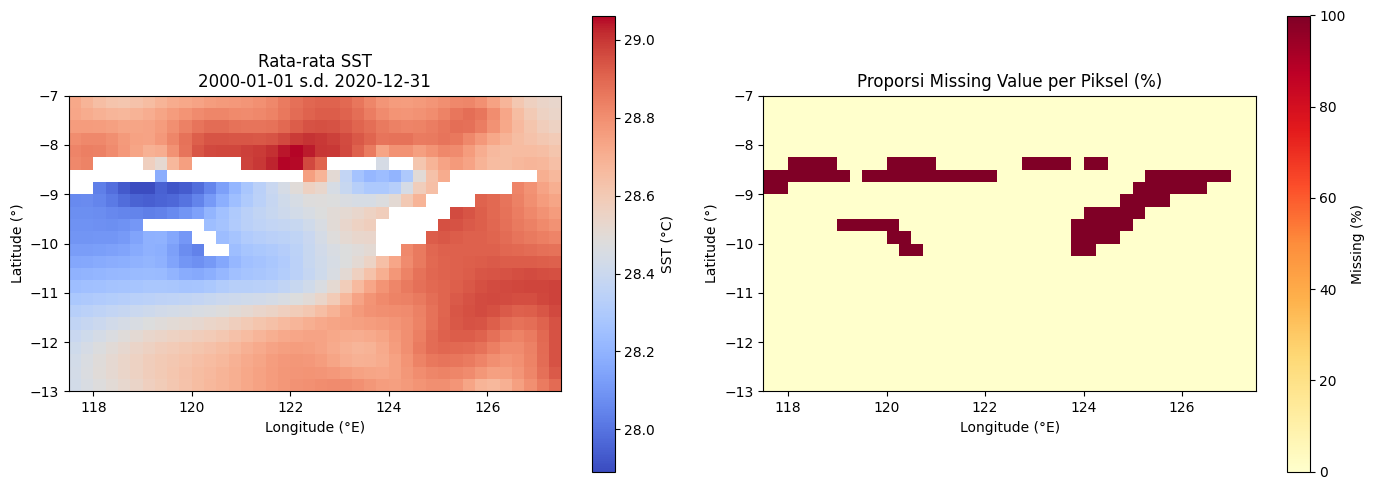

Peta disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\nb1_sst_coverage_map.png


In [6]:
# Peta cakupan SST
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Peta rata-rata SST
sst_mean = ds_sst["sst"].mean(dim="time")
im1 = axes[0].pcolormesh(
    ds_sst.lon, ds_sst.lat, sst_mean,
    cmap=cfg.COLORMAP_SST, shading="auto"
)
axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°)")
axes[0].set_title(f"Rata-rata SST\n{str(ds_sst.time.values[0])[:10]} s.d. "
                  f"{str(ds_sst.time.values[-1])[:10]}")
cb1 = plt.colorbar(im1, ax=axes[0], label="SST (°C)")
axes[0].set_aspect("equal")

# Panel 2: Proporsi missing value per piksel
nan_frac = np.isnan(ds_sst["sst"].values).mean(axis=0)
im2 = axes[1].pcolormesh(
    ds_sst.lon, ds_sst.lat, nan_frac * 100,
    cmap="YlOrRd", shading="auto", vmin=0, vmax=100
)
axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°)")
axes[1].set_title("Proporsi Missing Value per Piksel (%)")
cb2 = plt.colorbar(im2, ax=axes[1], label="Missing (%)")
axes[1].set_aspect("equal")

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb1_sst_coverage_map.png", dpi=cfg.FIGURE_DPI,
            bbox_inches="tight")
plt.show()
print(f"Peta disimpan: {cfg.FIGURES_DIR / 'nb1_sst_coverage_map.png'}")

### Grafik Deret Waktu SST Regional

Rata-rata spasial SST harian untuk memverifikasi pola temporal yang wajar.

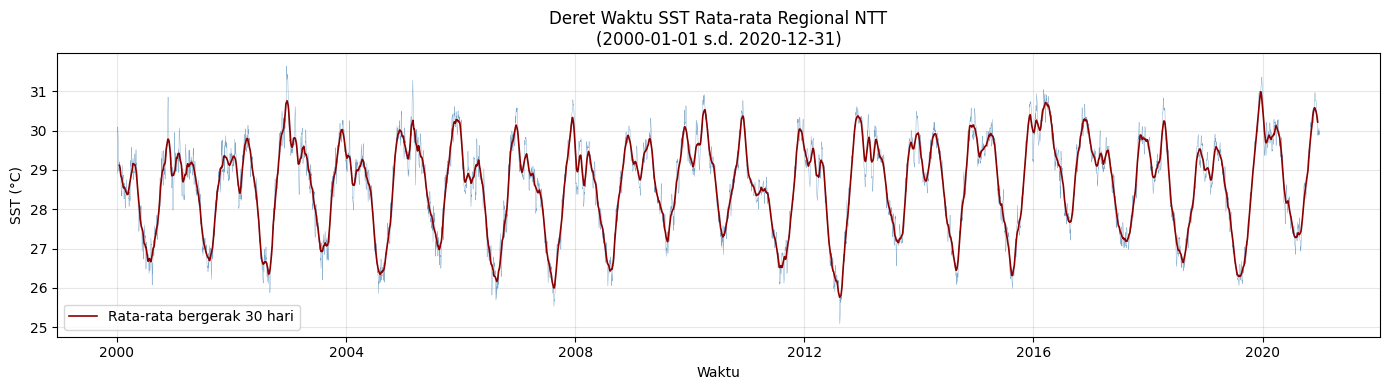

Grafik disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\nb1_sst_timeseries.png


In [7]:
# Deret waktu SST rata-rata wilayah
sst_regional = ds_sst["sst"].mean(dim=["lat", "lon"])

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ds_sst.time, sst_regional, linewidth=0.3, color="steelblue", alpha=0.7)

# Tambahkan rata-rata bergerak 30 hari
sst_rolling = sst_regional.rolling(time=30, center=True).mean()
ax.plot(ds_sst.time, sst_rolling, linewidth=1.2, color="darkred",
        label="Rata-rata bergerak 30 hari")

ax.set_xlabel("Waktu")
ax.set_ylabel("SST (°C)")
ax.set_title(f"Deret Waktu SST Rata-rata Regional NTT\n"
             f"({str(ds_sst.time.values[0])[:10]} s.d. "
             f"{str(ds_sst.time.values[-1])[:10]})")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb1_sst_timeseries.png", dpi=cfg.FIGURE_DPI,
            bbox_inches="tight")
plt.show()
print(f"Grafik disimpan: {cfg.FIGURES_DIR / 'nb1_sst_timeseries.png'}")

---
## 7. Ekspor Dataset SST Gabungan

Menyimpan dataset SST gabungan ke file NetCDF terverifikasi.

In [8]:
# Simpan dataset SST gabungan
print("Menyimpan dataset SST gabungan...")

# Tambahkan metadata
ds_sst.attrs["title"] = "SST Harian Gabungan - Perairan NTT"
ds_sst.attrs["source"] = "NOAA OISST v2.1 AVHRR-only daily"
ds_sst.attrs["spatial_resolution"] = "0.25 degree (~25 km)"
ds_sst.attrs["region"] = (f"Bounding box NTT: lon {cfg.LON_MIN}–{cfg.LON_MAX}°E, "
                           f"lat {cfg.LAT_MIN}–{cfg.LAT_MAX}°")
ds_sst.attrs["created_by"] = "Notebook 1 - Persiapan dan Penggabungan Data"
ds_sst.attrs["created_date"] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
ds_sst.attrs["note"] = ("Bounding box perkiraan. Bukan batas administrasi. "
                         "Gunakan mask darat/laut sebelum analisis spasial final.")

# Compute sebelum simpan (keluar dari dask lazy)
ds_sst_computed = ds_sst.compute()

output_path = cfg.SST_MERGED_OUTPUT
ds_sst_computed.to_netcdf(
    output_path,
    encoding={"sst": {"zlib": True, "complevel": 4, "dtype": "float32"}}
)

print(f"✅ Dataset SST disimpan: {output_path}")
print(f"   Ukuran: {output_path.stat().st_size / (1024*1024):.1f} MB")

# Verifikasi buka kembali
ds_verify = xr.open_dataset(output_path)
print(f"   Verifikasi: {dict(ds_verify.sizes)}")
print(f"   Waktu: {str(ds_verify.time.values[0])[:10]} s.d. {str(ds_verify.time.values[-1])[:10]}")
assert len(ds_verify.time) == len(ds_sst_computed.time), "Jumlah waktu tidak cocok!"
print("   ✅ Verifikasi berhasil.")
ds_verify.close()

Menyimpan dataset SST gabungan...


✅ Dataset SST disimpan: G:\My Drive\KLIMTROP\PBL\data\processed\sst_daily_2000_2020_ntt.nc
   Ukuran: 13.6 MB
   Verifikasi: {'time': 7671, 'lat': 24, 'lon': 40}
   Waktu: 2000-01-01 s.d. 2020-12-31
   ✅ Verifikasi berhasil.


---
## 8. Inventarisasi Chlorophyll-a

Memeriksa file ZIP bulanan dan NetCDF harian chlorophyll-a.  
**Sumber data:** ESA CCI Ocean Colour v6.0, resolusi ~4 km (~0.0417°).  
**Format:** ZIP bulanan berisi file NetCDF harian.

Data chlorophyll-a ditemukan di dua lokasi:
1. `chla_ntt_daily/` — ZIP bulanan (sumber utama)
2. `data_klorofil_ntt/` — NetCDF tahunan (sudah digabung sebelumnya, sebagian tahun)

In [9]:
# Inventarisasi chlorophyll-a
print("Inventarisasi Chlorophyll-a")
print("=" * 60)

# --- Periksa ZIP bulanan ---
zip_dirs = [cfg.CHLA_ZIP_DIR_PRIMARY, cfg.CHLA_ZIP_DIR_SECONDARY]
all_zips = []

for zip_dir in zip_dirs:
    if zip_dir.exists():
        zips = sorted(zip_dir.glob("chla_ntt_*.zip"))
        print(f"\nFolder: {zip_dir}")
        print(f"  ZIP ditemukan: {len(zips)}")
        for z in zips:
            # Parse tahun dan bulan dari nama file
            parts = z.stem.replace("chla_ntt_", "").split("_")
            try:
                tahun = int(parts[0])
                bulan = int(parts[1]) if len(parts) > 1 else None
            except (ValueError, IndexError):
                tahun, bulan = None, None
            
            all_zips.append({
                "file": z.name,
                "tahun": tahun,
                "bulan": bulan,
                "ukuran_MB": round(z.stat().st_size / (1024*1024), 2),
                "source_dir": str(zip_dir),
                "path": str(z)
            })

df_chla_zips = pd.DataFrame(all_zips)

if len(df_chla_zips) > 0:
    print(f"\nTotal ZIP chlorophyll-a: {len(df_chla_zips)}")
    
    # Ringkasan per tahun
    tahun_bulan = df_chla_zips.groupby("tahun")["bulan"].apply(
        lambda x: sorted(x.dropna().astype(int).tolist())
    )
    print("\nKetersediaan per tahun (nomor bulan):")
    for tahun, bulans in tahun_bulan.items():
        status = "✅ lengkap" if len(bulans) == 12 else f"⚠️  {len(bulans)}/12"
        print(f"  {int(tahun)}: {bulans}  {status}")
    
    # Cek tahun unik
    tahun_chla = sorted(df_chla_zips["tahun"].dropna().unique().astype(int))
    print(f"\nTahun tersedia: {tahun_chla[0]}–{tahun_chla[-1]}")
    print(f"Jumlah tahun  : {len(set(tahun_chla))}")
else:
    print("\n⚠️  Tidak ada file ZIP chlorophyll-a ditemukan!")

# --- Periksa NC tahunan yang sudah ada ---
print("\n" + "-" * 40)
print("File NetCDF tahunan chlorophyll-a (sudah digabung sebelumnya):")
if cfg.CHLA_NC_DIR.exists():
    nc_files = sorted(cfg.CHLA_NC_DIR.glob("chla_ntt_*.nc"))
    for f in nc_files:
        print(f"  {f.name} ({f.stat().st_size / (1024*1024):.1f} MB)")
    if len(nc_files) == 0:
        print("  (tidak ada)")
else:
    print("  Folder tidak ditemukan.")

Inventarisasi Chlorophyll-a

Folder: G:\My Drive\KLIMTROP\PBL\data\chla_ntt_daily
  ZIP ditemukan: 252

Total ZIP chlorophyll-a: 252

Ketersediaan per tahun (nomor bulan):
  2000: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2001: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2002: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2003: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2004: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2005: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2006: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2007: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2008: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2009: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2010: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2011: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2012: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  2013: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]  ✅ lengkap
  

---
## 9. Inspeksi Struktur Data Chlorophyll-a

Memeriksa variabel, dimensi, unit, resolusi, dan fill value dari file chlorophyll-a.  
Satu file sampel dari ZIP diinspeksi secara detail.

In [10]:
# Inspeksi satu file chlorophyll-a dari ZIP
print("Inspeksi file chlorophyll-a dari ZIP...")
print("=" * 60)

# Ambil satu ZIP sampel
sample_zip = None
for zip_dir in [cfg.CHLA_ZIP_DIR_PRIMARY, cfg.CHLA_ZIP_DIR_SECONDARY]:
    if zip_dir.exists():
        zips = sorted(zip_dir.glob("chla_ntt_*.zip"))
        if zips:
            sample_zip = zips[0]
            break

if sample_zip is None:
    print("⚠️  Tidak ada file ZIP untuk diinspeksi.")
else:
    print(f"ZIP sampel: {sample_zip.name}")
    
    with zipfile.ZipFile(sample_zip) as z:
        names = z.namelist()
        nc_names = [n for n in names if n.endswith('.nc')]
        print(f"Isi ZIP: {len(names)} file ({len(nc_names)} NetCDF)")
        print(f"Contoh nama file: {nc_names[0] if nc_names else 'N/A'}")
        
        if nc_names:
            # Ekstrak satu file untuk inspeksi
            with tempfile.TemporaryDirectory() as tmpdir:
                z.extract(nc_names[0], tmpdir)
                fpath = os.path.join(tmpdir, nc_names[0])
                
                ds_chla_sample = xr.open_dataset(fpath)
                
                print(f"\n--- Dataset Info ---")
                print(f"Variabel: {list(ds_chla_sample.data_vars)}")
                print(f"Dimensi : {dict(ds_chla_sample.sizes)}")
                print(f"Koordinat: {list(ds_chla_sample.coords)}")
                
                print(f"\n--- Detail Variabel ---")
                for var_name in ds_chla_sample.data_vars:
                    var = ds_chla_sample[var_name]
                    print(f"\n  '{var_name}':")
                    print(f"    dtype    : {var.dtype}")
                    print(f"    shape    : {var.shape}")
                    print(f"    dims     : {var.dims}")
                    print(f"    units    : {var.attrs.get('units', 'TIDAK ADA')}")
                    print(f"    long_name: {var.attrs.get('long_name', 'TIDAK ADA')[:80]}")
                    
                    if var.dims and len(var.shape) > 0 and var.shape[0] > 0:
                        vals = var.values.flatten()
                        valid = vals[~np.isnan(vals)]
                        if len(valid) > 0:
                            print(f"    min      : {valid.min():.6f}")
                            print(f"    max      : {valid.max():.6f}")
                            print(f"    NaN frac : {100*(len(vals)-len(valid))/len(vals):.1f}%")
                
                # Info koordinat
                if 'lat' in ds_chla_sample.coords:
                    lat = ds_chla_sample.lat
                    print(f"\n  Lat: {float(lat.min()):.4f} s.d. {float(lat.max()):.4f}, "
                          f"count={len(lat)}")
                    # Resolusi
                    lat_diff = np.diff(lat.values)
                    print(f"  Resolusi lat: ~{np.abs(lat_diff).mean():.6f}° "
                          f"(~{np.abs(lat_diff).mean() * 111:.2f} km)")
                
                if 'lon' in ds_chla_sample.coords:
                    lon = ds_chla_sample.lon
                    print(f"  Lon: {float(lon.min()):.4f} s.d. {float(lon.max()):.4f}, "
                          f"count={len(lon)}")
                
                if 'time' in ds_chla_sample.coords:
                    print(f"  Time: {ds_chla_sample.time.values}")
                
                # Atribut global penting
                print(f"\n--- Atribut Global (ringkasan) ---")
                for key in ['source', 'spatial_resolution', 'product_version',
                            'sensor', 'processing_level', 'title']:
                    if key in ds_chla_sample.attrs:
                        val = str(ds_chla_sample.attrs[key])[:100]
                        print(f"  {key}: {val}")
                
                ds_chla_sample.close()

Inspeksi file chlorophyll-a dari ZIP...
ZIP sampel: chla_ntt_2000_1.zip
Isi ZIP: 31 file (31 NetCDF)
Contoh nama file: ESACCI-OC-L3S-CHLOR_A-MERGED-1D_DAILY_4km_GEO_PML_OCx-20000101-fv6.0.area-subset.-7.0.127.5.-13.0.117.5.nc



--- Dataset Info ---
Variabel: ['MERIS_nobs', 'MODISA_nobs', 'OLCI-A_nobs', 'OLCI-B_nobs', 'SeaWiFS_nobs', 'VIIRS_nobs', 'chlor_a', 'crs', 'total_nobs']
Dimensi : {'time': 1, 'lat': 144, 'lon': 240}
Koordinat: ['lat', 'lon', 'time']

--- Detail Variabel ---

  'MERIS_nobs':
    dtype    : float32
    shape    : (1, 144, 240)
    dims     : ('time', 'lat', 'lon')
    units    : TIDAK ADA
    long_name: Count of the number of observations from the MERIS sensor contributing to this b

  'MODISA_nobs':
    dtype    : float32
    shape    : (1, 144, 240)
    dims     : ('time', 'lat', 'lon')
    units    : TIDAK ADA
    long_name: Count of the number of observations from the MODIS (Aqua) sensor contributing to

  'OLCI-A_nobs':
    dtype    : float32
    shape    : (1, 144, 240)
    dims     : ('time', 'lat', 'lon')
    units    : TIDAK ADA
    long_name: Count of the number of observations from the OLCI A sensor contributing to this 

  'OLCI-B_nobs':
    dtype    : float32
    shape    :

---
## 10. Ekstraksi dan Penggabungan Chlorophyll-a

Mengekstrak file NetCDF harian dari setiap ZIP bulanan, lalu menggabungkan menjadi satu dataset.  

**Strategi:**
1. Untuk setiap ZIP, baca file NetCDF harian dari dalam ZIP (tanpa ekstraksi ke disk) 
2. Gabungkan semua file harian menjadi satu dataset
3. Hanya ambil variabel `chlor_a` dan `total_nobs` untuk efisiensi
4. Pertahankan resolusi harian, **tidak** diagregasi ke bulanan di tahap ini

**Catatan penting:**
- Data chlorophyll-a mungkin baru tersedia mulai tahun 2000 (SeaWiFS) atau 2003 (MODIS Aqua)
- Missing value (NaN) mencerminkan tutupan awan dan tidak diubah menjadi nol

In [11]:
# Ekstraksi dan penggabungan chlorophyll-a dari ZIP
from concurrent.futures import ThreadPoolExecutor

print("Memproses chlorophyll-a dari file ZIP...")
print("=" * 60)

# Tentukan sumber ZIP utama
chla_zip_dir = None
for d in [cfg.CHLA_ZIP_DIR_PRIMARY, cfg.CHLA_ZIP_DIR_SECONDARY]:
    if d.exists() and len(list(d.glob("chla_ntt_*.zip"))) > 0:
        chla_zip_dir = d
        break

if chla_zip_dir is None:
    print("Tidak ada folder ZIP chlorophyll-a yang ditemukan!")
    print("Proses chlorophyll-a dilewati.")
    ds_chla_combined = None
else:
    zip_files = sorted(chla_zip_dir.glob("chla_ntt_*.zip"))
    print(f"Sumber ZIP   : {chla_zip_dir}")
    print(f"Jumlah ZIP   : {len(zip_files)}")
    
    yearly_datasets = []
    files_gagal = []
    files_berhasil = 0
    total_nc_files = 0
    
    # Kelompokkan zip berdasarkan tahun untuk pemrosesan per tahun
    zip_by_year = {}
    for zf in zip_files:
        parts = zf.stem.replace("chla_ntt_", "").split("_")
        yr = int(parts[0]) if parts[0].isdigit() else 0
        zip_by_year.setdefault(yr, []).append(zf)
    
    def _read_nc_from_zip(zf_path):
        daily = []
        gagal = []
        with zipfile.ZipFile(zf_path) as z:
            nc_names = sorted([n for n in z.namelist() if n.endswith('.nc')])
            for nc_name in nc_names:
                try:
                    with z.open(nc_name) as nc_file:
                        nc_bytes = nc_file.read()
                    with xr.open_dataset(io.BytesIO(nc_bytes)) as ds_daily:
                        vars_to_keep = [v for v in ['chlor_a', 'total_nobs'] if v in ds_daily]
                        if vars_to_keep:
                            daily.append(ds_daily[vars_to_keep].load())
                except Exception as e:
                    gagal.append({"zip": zf_path.name, "nc": nc_name, "error": str(e)})
        return daily, gagal, len(nc_names)

    for yr in sorted(zip_by_year.keys()):
        interim_file = cfg.INTERIM_DIR / f"chla_daily_{yr}.nc"
        if interim_file.exists():
            ds_yr = xr.open_dataset(interim_file).load()
            yearly_datasets.append(ds_yr)
            n_d = len(ds_yr.time)
            files_berhasil += n_d
            total_nc_files += n_d
            print(f"  Tahun {yr}: {n_d} hari dimuat dari cache interim.")
            continue
            
        yr_zips = zip_by_year[yr]
        yr_daily = []
        with ThreadPoolExecutor(max_workers=6) as executor:
            results = list(executor.map(_read_nc_from_zip, yr_zips))
            
        for daily_list, fail_list, n_nc in results:
            yr_daily.extend(daily_list)
            files_gagal.extend(fail_list)
            total_nc_files += n_nc
            files_berhasil += len(daily_list)
        
        if yr_daily:
            ds_yr = xr.concat(yr_daily, dim="time").sortby("time")
            encoding = {v: {"zlib": True, "complevel": 3, "dtype": "float32"} for v in ds_yr.data_vars}
            ds_yr.to_netcdf(interim_file, encoding=encoding)
            yearly_datasets.append(ds_yr)
            print(f"  Tahun {yr}: {len(yr_daily)} hari digabung dan disimpan ke interim.")
    
    print(f"\nHasil pemrosesan:")
    print(f"  Total file NC dalam ZIP : {total_nc_files}")
    print(f"  Berhasil dibaca         : {files_berhasil}")
    print(f"  Gagal                   : {len(files_gagal)}")
    
    if files_gagal:
        df_gagal = pd.DataFrame(files_gagal)
        print(f"\nFile gagal:")
        print(df_gagal.head(20).to_string(index=False))
        df_gagal.to_csv(cfg.LOGS_DIR / "chla_extraction_failures.csv", index=False)
    
    # Gabungkan semua dataset tahunan
    if yearly_datasets:
        print(f"\nMenggabungkan {len(yearly_datasets)} tahun dataset chlorophyll-a...")
        ds_chla_combined = xr.concat(yearly_datasets, dim="time")
        ds_chla_combined = ds_chla_combined.sortby("time")
        
        # Cek dan hapus duplikat waktu
        times = pd.DatetimeIndex(ds_chla_combined.time.values)
        n_dup = times.duplicated().sum()
        if n_dup > 0:
            print(f"Peringatan: {n_dup} timestamp duplikat. Mengambil nilai pertama...")
            ds_chla_combined = ds_chla_combined.sel(time=~times.duplicated())
        
        print(f"\nDataset chlorophyll-a gabungan:")
        print(f"  Variabel  : {list(ds_chla_combined.data_vars)}")
        print(f"  Dimensi   : {dict(ds_chla_combined.sizes)}")
        print(f"  Waktu     : {str(ds_chla_combined.time.values[0])[:10]} s.d. "
              f"{str(ds_chla_combined.time.values[-1])[:10]}")
        print(f"  Jumlah hari: {len(ds_chla_combined.time)}")
        print(f"  Lat       : {float(ds_chla_combined.lat.min()):.4f} s.d. "
              f"{float(ds_chla_combined.lat.max()):.4f}")
        print(f"  Lon       : {float(ds_chla_combined.lon.min()):.4f} s.d. "
              f"{float(ds_chla_combined.lon.max()):.4f}")
        print(f"  Grid      : {len(ds_chla_combined.lat)} lat x {len(ds_chla_combined.lon)} lon")
        
        # Statistik
        if 'chlor_a' in ds_chla_combined:
            chla_vals = ds_chla_combined['chlor_a'].values.flatten()
            valid = chla_vals[~np.isnan(chla_vals)]
            print(f"\n  Statistik chlor_a:")
            print(f"    Total piksel : {len(chla_vals):,}")
            print(f"    Valid        : {len(valid):,} ({100*len(valid)/len(chla_vals):.1f}%)")
            print(f"    Min          : {valid.min():.6f} mg/m³")
            print(f"    Max          : {valid.max():.4f} mg/m³")
            print(f"    Mean         : {valid.mean():.4f} mg/m³")
            print(f"    Median       : {np.median(valid):.4f} mg/m³")
    else:
        print("Tidak ada dataset chlorophyll-a berhasil diproses!")
        ds_chla_combined = None

Memproses chlorophyll-a dari file ZIP...
Sumber ZIP   : G:\My Drive\KLIMTROP\PBL\data\chla_ntt_daily
Jumlah ZIP   : 252


  Tahun 2000: 365 hari dimuat dari cache interim.


  Tahun 2001: 364 hari dimuat dari cache interim.


  Tahun 2002: 365 hari dimuat dari cache interim.


  Tahun 2003: 365 hari dimuat dari cache interim.


...

  Tahun 2019: 365 hari dimuat dari cache interim.


  Tahun 2020: 366 hari dimuat dari cache interim.

Hasil pemrosesan:
  Total file NC dalam ZIP : 7669
  Berhasil dibaca         : 7669
  Gagal                   : 0

Menggabungkan 21 tahun dataset chlorophyll-a...



Dataset chlorophyll-a gabungan:
  Variabel  : ['chlor_a', 'total_nobs']
  Dimensi   : {'time': 7669, 'lat': 144, 'lon': 240}
  Waktu     : 2000-01-01 s.d. 2020-12-31
  Jumlah hari: 7669
  Lat       : -12.9792 s.d. -7.0208
  Lon       : 117.5208 s.d. 127.4792
  Grid      : 144 lat x 240 lon



  Statistik chlor_a:
    Total piksel : 265,040,640
    Valid        : 101,739,299 (38.4%)
    Min          : 0.001000 mg/m³
    Max          : 93.8350 mg/m³
    Mean         : 0.2933 mg/m³


    Median       : 0.2071 mg/m³


### Peta Cakupan Chlorophyll-a

Visualisasi untuk quality control cakupan data chlorophyll-a.

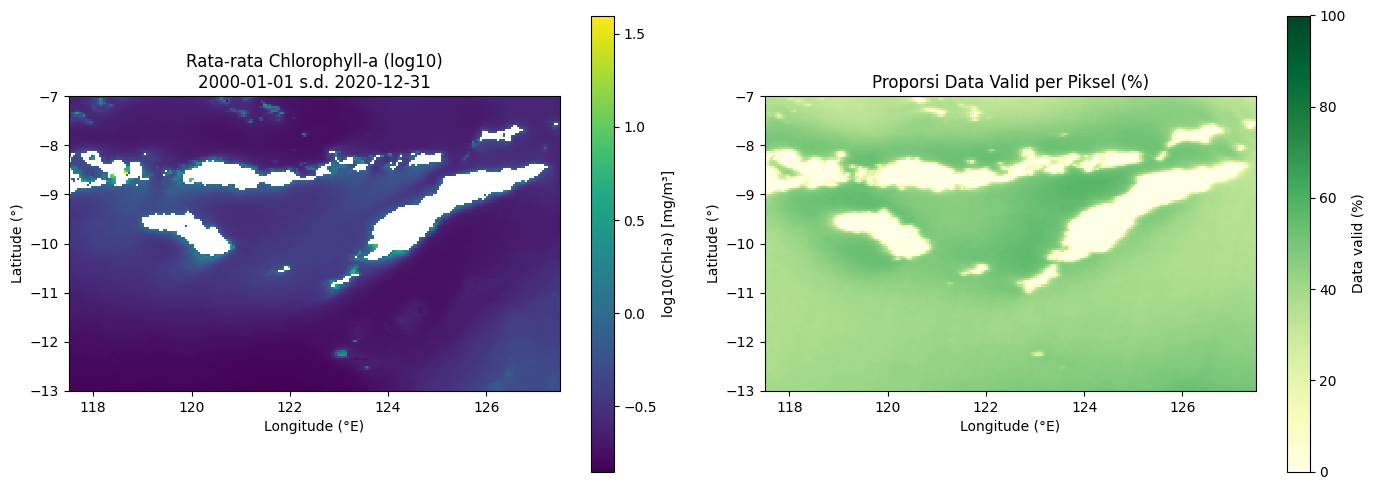

Peta disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\nb1_chla_coverage_map.png


In [12]:
# Peta cakupan chlorophyll-a
if ds_chla_combined is not None and 'chlor_a' in ds_chla_combined:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Panel 1: Rata-rata chlor_a (log scale karena distribusi skewed)
    chla_mean = ds_chla_combined["chlor_a"].mean(dim="time")
    im1 = axes[0].pcolormesh(
        ds_chla_combined.lon, ds_chla_combined.lat,
        np.log10(chla_mean.where(chla_mean > 0)),
        cmap=cfg.COLORMAP_CHLA, shading="auto"
    )
    axes[0].set_xlabel("Longitude (°E)")
    axes[0].set_ylabel("Latitude (°)")
    axes[0].set_title(f"Rata-rata Chlorophyll-a (log10)\n"
                      f"{str(ds_chla_combined.time.values[0])[:10]} s.d. "
                      f"{str(ds_chla_combined.time.values[-1])[:10]}")
    cb1 = plt.colorbar(im1, ax=axes[0], label="log10(Chl-a) [mg/m³]")
    axes[0].set_aspect("equal")
    
    # Panel 2: Proporsi data valid per piksel
    valid_frac = (~np.isnan(ds_chla_combined["chlor_a"])).mean(dim="time") * 100
    im2 = axes[1].pcolormesh(
        ds_chla_combined.lon, ds_chla_combined.lat,
        valid_frac,
        cmap="YlGn", shading="auto", vmin=0, vmax=100
    )
    axes[1].set_xlabel("Longitude (°E)")
    axes[1].set_ylabel("Latitude (°)")
    axes[1].set_title("Proporsi Data Valid per Piksel (%)")
    cb2 = plt.colorbar(im2, ax=axes[1], label="Data valid (%)")
    axes[1].set_aspect("equal")
    
    plt.tight_layout()
    fig.savefig(cfg.FIGURES_DIR / "nb1_chla_coverage_map.png", dpi=cfg.FIGURE_DPI,
                bbox_inches="tight")
    plt.show()
    print(f"Peta disimpan: {cfg.FIGURES_DIR / 'nb1_chla_coverage_map.png'}")
else:
    print("⚠️  Dataset chlorophyll-a tidak tersedia, peta dilewati.")

---
## 11. Ekspor Dataset Chlorophyll-a Gabungan

Menyimpan dataset chlorophyll-a harian gabungan.

In [13]:
# Simpan dataset chlorophyll-a gabungan
if ds_chla_combined is not None:
    print("Menyimpan dataset chlorophyll-a gabungan...")
    
    # Tambahkan metadata
    ds_chla_combined.attrs["title"] = "Chlorophyll-a Harian Gabungan - Perairan NTT"
    ds_chla_combined.attrs["source"] = "ESA CCI Ocean Colour v6.0 (Copernicus C3S)"
    ds_chla_combined.attrs["spatial_resolution"] = "~4 km (~0.0417 degree)"
    ds_chla_combined.attrs["region"] = (
        f"Bounding box NTT: lon {cfg.LON_MIN}–{cfg.LON_MAX}°E, "
        f"lat {cfg.LAT_MIN}–{cfg.LAT_MAX}°"
    )
    ds_chla_combined.attrs["created_by"] = "Notebook 1 - Persiapan dan Penggabungan Data"
    ds_chla_combined.attrs["created_date"] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    ds_chla_combined.attrs["note"] = (
        "Data harian asli dipertahankan. Missing value (NaN) berasal dari tutupan awan "
        "dan tidak diubah menjadi nol. Agregasi bulanan dilakukan di notebook analisis."
    )
    
    output_path = cfg.CHLA_MERGED_OUTPUT
    
    # Encoding untuk kompresi
    encoding = {}
    for var in ds_chla_combined.data_vars:
        encoding[var] = {"zlib": True, "complevel": 4, "dtype": "float32"}
    
    ds_chla_combined.to_netcdf(output_path, encoding=encoding)
    
    print(f"✅ Dataset chlorophyll-a disimpan: {output_path}")
    print(f"   Ukuran: {output_path.stat().st_size / (1024*1024):.1f} MB")
    
    # Verifikasi
    ds_v = xr.open_dataset(output_path)
    print(f"   Verifikasi: {dict(ds_v.sizes)}")
    print(f"   Waktu: {str(ds_v.time.values[0])[:10]} s.d. {str(ds_v.time.values[-1])[:10]}")
    assert len(ds_v.time) == len(ds_chla_combined.time), "Jumlah waktu tidak cocok!"
    print("   ✅ Verifikasi berhasil.")
    ds_v.close()
else:
    print("⚠️  Dataset chlorophyll-a tidak tersedia, ekspor dilewati.")

Menyimpan dataset chlorophyll-a gabungan...


✅ Dataset chlorophyll-a disimpan: G:\My Drive\KLIMTROP\PBL\data\processed\chlorophyll_a_daily_ntt.nc
   Ukuran: 621.0 MB


   Verifikasi: {'time': 7669, 'lat': 144, 'lon': 240}
   Waktu: 2000-01-01 s.d. 2020-12-31
   ✅ Verifikasi berhasil.


---
## 12. Pemeriksaan SHP (Opsional)

Memeriksa file SHP batas administrasi kabupaten/kota NTT jika tersedia.  
**Catatan:** SHP bersifat opsional untuk overlay peta, bukan syarat analisis SST atau MHW.  
SHP tidak menggantikan garis pantai dan tidak menentukan batas analisis laut.

In [14]:
# Pemeriksaan SHP (opsional)
print("Pemeriksaan SHP")
print("=" * 60)

shp_found = False

# Cari file SHP di berbagai lokasi yang mungkin
search_dirs = [
    cfg.SHP_DIR,
    cfg.DATA_DIR / "shp",
    cfg.DATA_DIR / "raw",
    cfg.PROJECT_ROOT / "shp"
]

shp_files = []
for d in search_dirs:
    if d.exists():
        shp_files.extend(d.glob("**/*.shp"))

if shp_files:
    print(f"File SHP ditemukan: {len(shp_files)}")
    for sf in shp_files:
        print(f"  {sf}")
        
        # Cek file pendamping
        companions = [".shx", ".dbf", ".prj", ".cpg"]
        for ext in companions:
            comp = sf.with_suffix(ext)
            status = "✅" if comp.exists() else "❌ HILANG"
            print(f"    {ext}: {status}")
    
    # Coba buka dengan geopandas
    try:
        import geopandas as gpd
        gdf = gpd.read_file(shp_files[0])
        print(f"\n  CRS       : {gdf.crs}")
        print(f"  Geometri  : {gdf.geometry.geom_type.unique()}")
        print(f"  Jumlah fitur: {len(gdf)}")
        print(f"  Kolom     : {list(gdf.columns)}")
        print(f"  Bounds    : {gdf.total_bounds}")
        shp_found = True
    except ImportError:
        print("\n⚠️  geopandas tidak tersedia. SHP tidak diinspeksi lebih lanjut.")
    except Exception as e:
        print(f"\n⚠️  Gagal membaca SHP: {e}")
else:
    print("ℹ️  Tidak ada file SHP ditemukan.")
    print("  SHP bersifat opsional dan tidak menjadi syarat analisis.")
    print("  Jika diperlukan, letakkan file SHP di:", cfg.SHP_DIR)

Pemeriksaan SHP
ℹ️  Tidak ada file SHP ditemukan.
  SHP bersifat opsional dan tidak menjadi syarat analisis.
  Jika diperlukan, letakkan file SHP di: G:\My Drive\KLIMTROP\PBL\data\raw\shp


---
## 13. Pemeriksaan Data Tangkapan Ikan (Opsional)

Memeriksa ketersediaan data tangkapan tongkol dan cakalang.  
Data tangkapan hanya digunakan untuk konteks deskriptif/kualitatif di Notebook 6.

In [15]:
# Pemeriksaan data tangkapan ikan
print("Pemeriksaan Data Tangkapan Ikan")
print("=" * 60)

catch_found = False
catch_dirs = [
    cfg.CATCH_DIR,
    cfg.DATA_DIR / "catch",
    cfg.DATA_DIR / "raw" / "catch",
    cfg.DATA_DIR / "tangkapan"
]

catch_files = []
for d in catch_dirs:
    if d.exists():
        for ext in ["*.csv", "*.xlsx", "*.xls"]:
            catch_files.extend(d.glob(ext))

if catch_files:
    print(f"File data tangkapan ditemukan: {len(catch_files)}")
    for cf in catch_files:
        print(f"  {cf.name} ({cf.stat().st_size / 1024:.1f} KB)")
    catch_found = True
else:
    print("ℹ️  Tidak ada file data tangkapan ditemukan.")
    print("  Data tangkapan bersifat opsional (Notebook 6).")
    print("  Spesies target: tongkol dan cakalang.")
    print("  Jika tersedia, letakkan di:", cfg.CATCH_DIR)

Pemeriksaan Data Tangkapan Ikan
ℹ️  Tidak ada file data tangkapan ditemukan.
  Data tangkapan bersifat opsional (Notebook 6).
  Spesies target: tongkol dan cakalang.
  Jika tersedia, letakkan di: G:\My Drive\KLIMTROP\PBL\data\raw\catch


---
## 14. Pemeriksaan Kualitas dan Laporan Inventaris

Menyusun laporan kualitas data untuk semua dataset yang ditemukan.

In [16]:
# Buat laporan inventaris data
print("Menyusun Laporan Inventaris dan Kualitas Data")
print("=" * 60)

inventory_records = []

# --- SST ---
for f in sorted(cfg.SST_RAW_DIR.glob("sst_ntt_*.nc")):
    try:
        ds = xr.open_dataset(f)
        n_time = len(ds.time)
        start = str(ds.time.values[0])[:10]
        end = str(ds.time.values[-1])[:10]
        
        sst_data = ds["sst"].values
        nan_frac = np.isnan(sst_data).sum() / sst_data.size * 100
        
        inventory_records.append({
            "tipe_data": "SST",
            "file": f.name,
            "ukuran_MB": round(f.stat().st_size / (1024*1024), 2),
            "variabel": "sst",
            "unit": "Celsius",
            "resolusi": "0.25°",
            "n_timestep": n_time,
            "tanggal_awal": start,
            "tanggal_akhir": end,
            "missing_pct": round(nan_frac, 2),
            "status": "OK"
        })
        ds.close()
    except Exception as e:
        inventory_records.append({
            "tipe_data": "SST",
            "file": f.name,
            "status": f"ERROR: {str(e)[:50]}"
        })

# --- Chlorophyll-a ZIP ---
for d in [cfg.CHLA_ZIP_DIR_PRIMARY, cfg.CHLA_ZIP_DIR_SECONDARY]:
    if d.exists():
        for f in sorted(d.glob("chla_ntt_*.zip")):
            try:
                with zipfile.ZipFile(f) as z:
                    nc_count = len([n for n in z.namelist() if n.endswith('.nc')])
                inventory_records.append({
                    "tipe_data": "Chlorophyll-a ZIP",
                    "file": f.name,
                    "ukuran_MB": round(f.stat().st_size / (1024*1024), 2),
                    "variabel": "chlor_a",
                    "unit": "mg/m³",
                    "resolusi": "~4 km",
                    "n_timestep": nc_count,
                    "status": "OK"
                })
            except Exception as e:
                inventory_records.append({
                    "tipe_data": "Chlorophyll-a ZIP",
                    "file": f.name,
                    "status": f"ERROR: {str(e)[:50]}"
                })
        break  # Hanya dari satu direktori untuk menghindari duplikat

df_inventory = pd.DataFrame(inventory_records)

# Simpan inventaris
inv_path = cfg.DATA_INVENTORY_OUTPUT
df_inventory.to_csv(inv_path, index=False)
print(f"✅ Inventaris disimpan: {inv_path}")
print(f"   Total file: {len(df_inventory)}")
print()

# Tampilkan ringkasan
print("Ringkasan Inventaris:")
print(df_inventory.groupby("tipe_data").agg(
    jumlah_file=("file", "count"),
    ukuran_total_MB=("ukuran_MB", "sum")
).to_string())

Menyusun Laporan Inventaris dan Kualitas Data


✅ Inventaris disimpan: G:\My Drive\KLIMTROP\PBL\outputs\reports\data_inventory.csv
   Total file: 273

Ringkasan Inventaris:
                   jumlah_file  ukuran_total_MB
tipe_data                                      
Chlorophyll-a ZIP          252          1512.16
SST                         21            14.38


In [17]:
# Buat laporan kualitas data
print("\nLaporan Kualitas Data")
print("=" * 60)

quality_records = []

# SST Quality
if ds_sst is not None:
    times_sst = pd.DatetimeIndex(ds_sst.time.values)
    sst_data = ds_sst["sst"].values
    
    quality_records.append({
        "dataset": "SST Gabungan",
        "sumber": "NOAA OISST v2.1",
        "variabel": "sst",
        "unit": "Celsius",
        "resolusi_spasial": "0.25° (~25 km)",
        "resolusi_temporal": "harian",
        "periode_awal": str(times_sst[0])[:10],
        "periode_akhir": str(times_sst[-1])[:10],
        "jumlah_hari": len(times_sst),
        "timestamp_duplikat": int(times_sst.duplicated().sum()),
        "grid_lat": len(ds_sst.lat),
        "grid_lon": len(ds_sst.lon),
        "missing_pct": round(np.isnan(sst_data).sum() / sst_data.size * 100, 2),
        "min_nilai": round(float(np.nanmin(sst_data)), 2),
        "max_nilai": round(float(np.nanmax(sst_data)), 2),
        "mean_nilai": round(float(np.nanmean(sst_data)), 2),
        "file_output": str(cfg.SST_MERGED_OUTPUT.name),
        "status": "OK"
    })

# Chlorophyll-a Quality
if ds_chla_combined is not None:
    times_chla = pd.DatetimeIndex(ds_chla_combined.time.values)
    chla_data = ds_chla_combined["chlor_a"].values
    
    quality_records.append({
        "dataset": "Chlorophyll-a Gabungan",
        "sumber": "ESA CCI OC v6.0",
        "variabel": "chlor_a",
        "unit": "mg/m³",
        "resolusi_spasial": "~4 km (~0.0417°)",
        "resolusi_temporal": "harian",
        "periode_awal": str(times_chla[0])[:10],
        "periode_akhir": str(times_chla[-1])[:10],
        "jumlah_hari": len(times_chla),
        "timestamp_duplikat": int(times_chla.duplicated().sum()),
        "grid_lat": len(ds_chla_combined.lat),
        "grid_lon": len(ds_chla_combined.lon),
        "missing_pct": round(np.isnan(chla_data).sum() / chla_data.size * 100, 2),
        "min_nilai": round(float(np.nanmin(chla_data)), 6),
        "max_nilai": round(float(np.nanmax(chla_data)), 4),
        "mean_nilai": round(float(np.nanmean(chla_data)), 4),
        "file_output": str(cfg.CHLA_MERGED_OUTPUT.name),
        "status": "OK"
    })

df_quality = pd.DataFrame(quality_records)

# Simpan laporan kualitas
quality_path = cfg.DATA_QUALITY_OUTPUT
df_quality.to_csv(quality_path, index=False)
print(f"✅ Laporan kualitas disimpan: {quality_path}")
print()

# Tampilkan
print("Detail Kualitas Data:")
for _, row in df_quality.iterrows():
    print(f"\n  📊 {row['dataset']}")
    print(f"     Sumber        : {row['sumber']}")
    print(f"     Periode       : {row['periode_awal']} s.d. {row['periode_akhir']}")
    print(f"     Jumlah hari   : {row['jumlah_hari']}")
    print(f"     Grid          : {row['grid_lat']} × {row['grid_lon']}")
    print(f"     Missing       : {row['missing_pct']}%")
    print(f"     Rentang nilai : {row['min_nilai']} – {row['max_nilai']} {row['unit']}")
    print(f"     Output        : {row['file_output']}")


Laporan Kualitas Data


✅ Laporan kualitas disimpan: G:\My Drive\KLIMTROP\PBL\outputs\reports\data_quality_report.csv

Detail Kualitas Data:

  📊 SST Gabungan
     Sumber        : NOAA OISST v2.1
     Periode       : 2000-01-01 s.d. 2020-12-31
     Jumlah hari   : 7671
     Grid          : 24 × 40
     Missing       : 7.92%
     Rentang nilai : 23.36 – 33.0 Celsius
     Output        : sst_daily_2000_2020_ntt.nc

  📊 Chlorophyll-a Gabungan
     Sumber        : ESA CCI OC v6.0
     Periode       : 2000-01-01 s.d. 2020-12-31
     Jumlah hari   : 7669
     Grid          : 144 × 240
     Missing       : 61.61%
     Rentang nilai : 0.001 – 93.835 mg/m³
     Output        : chlorophyll_a_daily_ntt.nc


---
## 15. Keterbatasan

1. **Bounding box:** Batas koordinat (lon 117.5–127.5°E, lat 13°S–7°S) adalah perkiraan wilayah NTT, bukan batas administrasi resmi atau batas ekosistem laut. Analisis di area pinggir mungkin mencakup perairan di luar NTT.

2. **SST resolusi:** Data SST NOAA OISST v2.1 memiliki resolusi asli 0.25° (~25 km). Ini adalah produk interpolasi optimal, bukan pengamatan langsung di setiap titik grid.

3. **Chlorophyll-a missing value:** Proporsi missing value pada data chlorophyll-a umumnya tinggi (akibat tutupan awan, terutama pada musim hujan). Missing value **tidak diubah menjadi nol** dan harus diperhatikan dalam analisis selanjutnya.

4. **Periode data:** 
   - SST mencakup 2000–2020 (21 tahun), bukan klimatologi standar 30 tahun.
   - Chlorophyll-a mungkin tidak mencakup seluruh periode 2000–2020; periode aktual harus diperiksa dari output notebook ini.

5. **SHP:** File SHP batas administrasi belum ditemukan. Jika diperlukan untuk overlay peta, letakkan file SHP di folder yang sesuai.

6. **Data tangkapan:** Data tangkapan tongkol dan cakalang belum tersedia. Notebook 6 akan membahas keterbatasan ini.

---
## 16. Checklist Evaluasi

| No | Kriteria | Status |
|----|----------|--------|
| 1 | Semua file SST tercatat dalam inventaris | ✅ / ⚠️ |
| 2 | Variabel, unit, dan dimensi SST diverifikasi | ✅ |
| 3 | Timestamp duplikat ditangani | ✅ |
| 4 | Missing value TIDAK diubah menjadi nol | ✅ |
| 5 | Dataset SST gabungan berhasil diekspor | ✅ / ⚠️ |
| 6 | File SST gabungan dapat dibuka kembali | ✅ / ⚠️ |
| 7 | File chlorophyll-a tercatat dalam inventaris | ✅ / ⚠️ |
| 8 | Variabel, unit chlorophyll-a diverifikasi | ✅ |
| 9 | Dataset chlorophyll-a berhasil diekspor | ✅ / ⚠️ |
| 10 | Laporan inventaris dan kualitas data dibuat | ✅ |
| 11 | Peta cakupan untuk QC visual dibuat | ✅ |
| 12 | Periode aktual dicatat | ✅ |

> **Catatan:** Status ✅ / ⚠️ diisi berdasarkan hasil eksekusi aktual di atas.

---
## 17. Ringkasan Keluaran untuk Notebook Selanjutnya

### File yang Dihasilkan
| File | Deskripsi | Digunakan Oleh |
|------|-----------|---------------|
| `sst_daily_2000_2020_ntt.nc` | SST harian gabungan | Notebook 2 |
| `chlorophyll_a_daily_ntt.nc` | Chlorophyll-a harian gabungan | Notebook 3 |
| `data_inventory.csv` | Inventaris semua file | Referensi |
| `data_quality_report.csv` | Laporan kualitas data | Referensi |
| `nb1_sst_coverage_map.png` | Peta cakupan SST | QC |
| `nb1_chla_coverage_map.png` | Peta cakupan chlorophyll-a | QC |
| `nb1_sst_timeseries.png` | Deret waktu SST | QC |

### Informasi untuk Notebook Berikutnya
- **Notebook 2 (SST & MHW):** Gunakan `sst_daily_2000_2020_ntt.nc`. Variabel: `sst` (°C). Grid: 24×40 (0.25°). Periode: sesuai output aktual.
- **Notebook 3 (Chlorophyll-a):** Gunakan `chlorophyll_a_daily_ntt.nc`. Variabel: `chlor_a` (mg/m³). Grid: 144×240 (~4 km). Periode: sesuai output aktual.
- **SHP:** Belum tersedia. Opsional untuk overlay peta.
- **Data tangkapan:** Belum tersedia. Opsional untuk Notebook 6.

In [18]:
# Ringkasan akhir
print("=" * 60)
print("RINGKASAN NOTEBOOK 1 — PERSIAPAN DAN PENGGABUNGAN DATA")
print("=" * 60)

print(f"\n📁 File Output:")
outputs_check = [
    ("SST gabungan", cfg.SST_MERGED_OUTPUT),
    ("Chlorophyll-a gabungan", cfg.CHLA_MERGED_OUTPUT),
    ("Inventaris data", cfg.DATA_INVENTORY_OUTPUT),
    ("Laporan kualitas", cfg.DATA_QUALITY_OUTPUT),
]

for label, path in outputs_check:
    if path.exists():
        size = path.stat().st_size / (1024*1024)
        print(f"  ✅ {label}: {path.name} ({size:.1f} MB)")
    else:
        print(f"  ❌ {label}: TIDAK DITEMUKAN ({path.name})")

print(f"\n📊 Ringkasan Data:")
if ds_sst is not None:
    print(f"  SST: {str(ds_sst.time.values[0])[:10]} s.d. {str(ds_sst.time.values[-1])[:10]}, "
          f"{len(ds_sst.time)} hari, grid {len(ds_sst.lat)}×{len(ds_sst.lon)}")
if ds_chla_combined is not None:
    print(f"  Chl-a: {str(ds_chla_combined.time.values[0])[:10]} s.d. "
          f"{str(ds_chla_combined.time.values[-1])[:10]}, "
          f"{len(ds_chla_combined.time)} hari, grid "
          f"{len(ds_chla_combined.lat)}×{len(ds_chla_combined.lon)}")

print(f"\n⚠️  Data belum tersedia:")
if not shp_found:
    print("  - File SHP batas administrasi")
if not catch_found:
    print("  - Data tangkapan tongkol/cakalang")

print(f"\n▶️  Langkah selanjutnya:")
print("  1. Periksa peta cakupan dan deret waktu SST.")
print("  2. Jika data lengkap, lanjutkan ke Notebook 2 (Analisis SST dan Deteksi MHW).")
print("  3. Jika chlorophyll-a lengkap, lanjutkan juga ke Notebook 3.")
print("\nNotebook 1 selesai.")
print(f"Waktu: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

RINGKASAN NOTEBOOK 1 — PERSIAPAN DAN PENGGABUNGAN DATA

📁 File Output:
  ✅ SST gabungan: sst_daily_2000_2020_ntt.nc (13.6 MB)
  ✅ Chlorophyll-a gabungan: chlorophyll_a_daily_ntt.nc (621.0 MB)
  ✅ Inventaris data: data_inventory.csv (0.0 MB)
  ✅ Laporan kualitas: data_quality_report.csv (0.0 MB)

📊 Ringkasan Data:
  SST: 2000-01-01 s.d. 2020-12-31, 7671 hari, grid 24×40
  Chl-a: 2000-01-01 s.d. 2020-12-31, 7669 hari, grid 144×240

⚠️  Data belum tersedia:
  - File SHP batas administrasi
  - Data tangkapan tongkol/cakalang

▶️  Langkah selanjutnya:
  1. Periksa peta cakupan dan deret waktu SST.
  2. Jika data lengkap, lanjutkan ke Notebook 2 (Analisis SST dan Deteksi MHW).
  3. Jika chlorophyll-a lengkap, lanjutkan juga ke Notebook 3.

Notebook 1 selesai.
Waktu: 2026-10-25 11:04:35
